# 06 · Exploratorio (NO pre-registrado): curva de validación de H2 por época

**Advertencia.** Este análisis se agregó después de ver los resultados de H2, a pedido del equipo, para responder una duda: la curva de pérdida de entrenamiento (notebook 04) solo muestra que el modelo aprende **en los chips de entrenamiento**, no si generaliza.

**Diseño.**

* Se entrena el decodificador con el mismo protocolo de H2 (lr 3e-5, lote 4, BCE + Dice, salida de una máscara) en `train-core` (199 chips) y **se evalúa al final de cada época en `train-dev`** (51 chips que el modelo no ve). La partición `valid` **no se usa** aquí, para no contaminar la evaluación de H2.
* Para medir la brecha de generalización, también se evalúa en una muestra fija de 51 chips de `train-core`.
* Se extiende a **24 épocas** (el doble del protocolo) para ver si después de la época 12 aparece sobreajuste. Se usan 3 semillas.
* La evaluación usa los prompts deterministas v2.1, igual que en H2.

**Cómo leerlo.** Si el IoU en `train-dev` sube y se estabiliza, el modelo generaliza. Si sube en train y **baja** en `train-dev`, hay sobreajuste. Si ambos siguen subiendo en la época 12, el modelo estaba **subentrenado**.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inf659sam import config, data
from inf659sam.baseline import auto_prompts, iou_components, otsu_masks
from inf659sam.cache import load_embedding, save_json
from inf659sam.decoder_ft import decoder_state, load_decoder_state, load_training_set, train_decoder
from inf659sam.sam_utils import SamWrapper

config.setup_runtime(seed=0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})
parts = json.loads((config.RESULTS_DIR / "particiones_usadas.json").read_text(encoding="utf-8"))
CORE, DEV = parts["train_core"], parts["train_dev"]
LR, EPOCAS = 3e-5, 24
sam = SamWrapper()
PRE = decoder_state(sam)
items = load_training_set(CORE)
muestra_train = sorted(CORE)[:: max(1, len(CORE) // len(DEV))][: len(DEV)]
print(f"train-core {len(CORE)} | train-dev {len(DEV)} | muestra de train para la brecha {len(muestra_train)} | dispositivo {sam.device}")


def preparar(chips):
    """Embeddings, prompts deterministas v2.1 y etiquetas, calculados una sola vez."""
    out = []
    for c in chips:
        d = data.load_chip(c)
        om = otsu_masks(d["vv"], d["vh"])
        pts, lbs, k = auto_prompts(om["opened"], om["sensor_valid"])
        out.append({"emb": load_embedding(c), "pts": pts, "lbs": lbs, "k": k, "lab": d["label"]})
    return out


EV_DEV, EV_TRAIN = preparar(DEV), preparar(muestra_train)


def iou_global(conj):
    tp = fp = fn = 0
    for e in conj:
        lab = e["lab"]
        if e["k"] == 0:
            pred = np.zeros_like(lab, dtype=bool)
        else:
            r = sam.decode(e["emb"]["emb"], e["pts"], e["lbs"], e["emb"]["original_sizes"],
                           e["emb"]["reshaped_input_sizes"], multimask=False)
            pred = r["masks"][0]
        res = iou_components(pred, lab == 1, lab != -1)
        tp, fp, fn = tp + res["tp"], fp + res["fp"], fn + res["fn"]
    return tp / (tp + fp + fn)


def callback(ep):
    return {"iou_train_dev": iou_global(EV_DEV), "iou_train_muestra": iou_global(EV_TRAIN)}


load_decoder_state(sam, PRE)
base = callback(0)
print(f"Época 0 (SAM preentrenado): IoU train-dev {base['iou_train_dev']:.4f} | train {base['iou_train_muestra']:.4f}")
curvas = {}
for seed in config.SEEDS:
    load_decoder_state(sam, PRE)
    h = train_decoder(sam, items, seed=seed, lr=LR, epochs=EPOCAS, callback=callback)
    curvas[seed] = [{"epoca": 0, "perdida_media": None, **base}] + h["historial"]
    m12 = curvas[seed][12]
    mx = max(curvas[seed][1:], key=lambda r: r["iou_train_dev"])
    print(f"semilla {seed}: época 12 → dev {m12['iou_train_dev']:.4f} (train {m12['iou_train_muestra']:.4f}) | "
          f"máximo dev {mx['iou_train_dev']:.4f} en la época {mx['epoca']} | época 24 → dev {curvas[seed][-1]['iou_train_dev']:.4f} "
          f"({h['minutos']:.1f} min)")
load_decoder_state(sam, PRE)

Entorno: {'seed': 0, 'torch_threads': 8}


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights:  16%|█▌        | 49/314 [00:00<00:00, 478.39it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 1839.77it/s]

train-core 199 | train-dev 51 | muestra de train para la brecha 51 | dispositivo cuda


Época 0 (SAM preentrenado): IoU train-dev 0.1390 | train 0.1214


semilla 0: época 12 → dev 0.5804 (train 0.5328) | máximo dev 0.6139 en la época 19 | época 24 → dev 0.4996 (4.4 min)


semilla 1: época 12 → dev 0.5645 (train 0.5265) | máximo dev 0.5899 en la época 20 | época 24 → dev 0.5439 (4.4 min)


semilla 2: época 12 → dev 0.5739 (train 0.5631) | máximo dev 0.5739 en la época 16 | época 24 → dev 0.3374 (4.4 min)


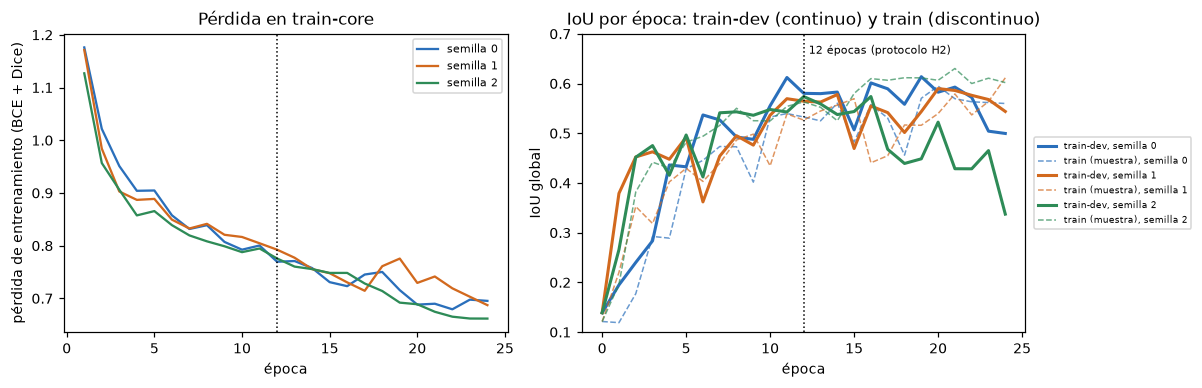

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cols = ["#2a6fbb", "#d2691e", "#2e8b57"]
for (seed, c), col in zip(curvas.items(), cols):
    ep = [r["epoca"] for r in c[1:]]
    axes[0].plot(ep, [r["perdida_media"] for r in c[1:]], color=col, label=f"semilla {seed}")
    axes[1].plot([r["epoca"] for r in c], [r["iou_train_dev"] for r in c], color=col, lw=2, label=f"train-dev, semilla {seed}")
    axes[1].plot([r["epoca"] for r in c], [r["iou_train_muestra"] for r in c], color=col, lw=1, ls="--", alpha=0.7,
                 label=f"train (muestra), semilla {seed}")
for a in axes:
    a.axvline(12, color="k", ls=":", lw=1)
    a.set_xlabel("época")
axes[0].set_ylabel("pérdida de entrenamiento (BCE + Dice)")
axes[0].set_title("Pérdida en train-core")
axes[0].legend(fontsize=7)
axes[1].set_ylabel("IoU global")
axes[1].set_title("IoU por época: train-dev (continuo) y train (discontinuo)")
axes[1].text(12.3, 0.66, "12 épocas (protocolo H2)", fontsize=7)
axes[1].set_ylim(0.1, 0.7)
axes[1].legend(fontsize=6, ncol=1, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig(config.FIG_DIR / "H2_curva_validacion_por_epoca.png")
plt.show()

In [3]:
filas = []
for seed, c in curvas.items():
    devs = [r["iou_train_dev"] for r in c[1:]]
    filas.append({"semilla": seed, "IoU dev época 12": c[12]["iou_train_dev"], "IoU train época 12": c[12]["iou_train_muestra"],
                  "brecha train−dev época 12": c[12]["iou_train_muestra"] - c[12]["iou_train_dev"],
                  "IoU dev máximo": max(devs), "época del máximo": int(np.argmax(devs)) + 1,
                  "IoU dev época 24": c[-1]["iou_train_dev"], "brecha época 24": c[-1]["iou_train_muestra"] - c[-1]["iou_train_dev"]})
df = pd.DataFrame(filas)
save_json({"advertencia": "exploratorio, no pre-registrado; evaluado en train-dev, valid no se usa",
           "lr": LR, "epocas": EPOCAS, "base_preentrenado": base, "curvas": {str(k): v for k, v in curvas.items()},
           "resumen": filas}, config.RESULTS_DIR / "exploratorio_curva_validacion.json")
df.round(4)

,semilla,IoU dev época 12,IoU train época 12,brecha train−dev época 12,IoU dev máximo,época del máximo,IoU dev época 24,brecha época 24
0,0,0.5804,0.5328,-0.0475,0.6139,19,0.4996,0.0603
1,1,0.5645,0.5265,-0.0380,0.5899,20,0.5439,0.0677
2,2,0.5739,0.5631,-0.0108,0.5739,16,0.3374,0.2646
